# Lab: Principal Component Analysis (INSTRUCTOR SOLUTIONS)

Reading: VanderPlas, *Python Data Science Handbook*, Section 5.09, "In Depth: Principal Component Analysis". Use it together with the lecture slides.

Instructions:

- Complete every code cell marked `# TODO`. Replace each `None` (or `...`) with your code. Each TODO includes a hint.
- After each TODO, run the cell marked `# Check your answer`. It prints PASS, or CHECK AGAIN with a short clue.
- Cells without a TODO are already complete. Run them and read the output.
- Write answers to the numbered questions in the markdown cell that follows each one.

Outline:

1. PCA by hand with NumPy (slides 5-10)
2. PCA in scikit-learn (slide 11)
3. The 200-point example from the book (slides 3, 12)
4. Handwritten digits and choosing the number of components (slides 13-14)
5. Noise filtering (slide 15)
6. Eigenfaces, optional (slide 16)
7. Scaling and outliers (slides 17-18)
8. Final exercise (slide 19)

In [1]:
# Setup: run this first
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.figsize"] = (6, 4)

def check(condition_fn, ok_msg, fail_msg):
    # Prints PASS if the condition holds, otherwise CHECK AGAIN with a clue.
    try:
        passed = bool(condition_fn())
    except Exception as e:
        passed = False
        fail_msg += f"   (error: {type(e).__name__}: {e})"
    print(("PASS: " + ok_msg) if passed else ("CHECK AGAIN: " + fail_msg))

## Part 1: PCA by hand (two temperature sensors)

Two sensors on the same machine take 5 readings. Each row is a reading and each column is a sensor.

The steps from slide 4:
1. Center the data by subtracting each column's mean.
2. Compute the covariance matrix $C = \frac{1}{n-1}X_c^\top X_c$.
3. Find the eigenvalues $\lambda$ and eigenvectors $v$ of $C$.
4. Sort them from largest to smallest $\lambda$.
5. Project the data: $Z = X_c V$.

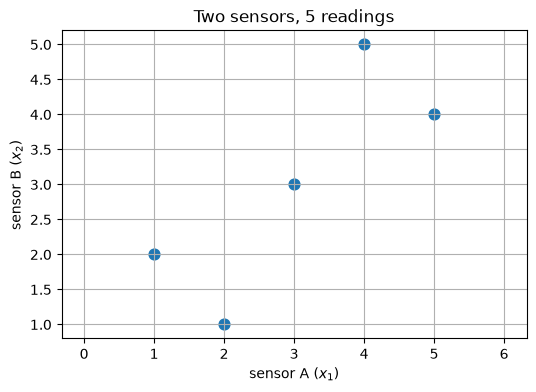

In [2]:
X = np.array([[1, 2],
              [2, 1],
              [3, 3],
              [4, 5],
              [5, 4]], dtype=float)
n = X.shape[0]

plt.scatter(X[:, 0], X[:, 1], s=60)
plt.xlabel("sensor A ($x_1$)"); plt.ylabel("sensor B ($x_2$)")
plt.axis("equal"); plt.grid(True); plt.title("Two sensors, 5 readings");

### Step 1: center the data
`X` has shape `(5, 2)`, so the mean has one value per column, shape `(2,)`.

In [3]:
# TODO 1a: mean of each column (should be [3, 3])
mean = np.mean(X, axis=0)

# TODO 1b: subtract the mean from every row
Xc = X - mean

print("mean =", mean)
print("Xc =\n", Xc)

mean = [3. 3.]
Xc =
 [[-2. -1.]
 [-1. -2.]
 [ 0.  0.]
 [ 1.  2.]
 [ 2.  1.]]


In [4]:
# Check your answer
check(lambda: np.allclose(mean, [3, 3]), "mean is correct", "mean should be [3, 3]: did you use axis=0?")
check(lambda: np.allclose(Xc.mean(axis=0), 0) and Xc.shape == (5, 2),
      "Xc is centered (column means are 0)", "Xc should have shape (5, 2) and column means of 0")

PASS: mean is correct
PASS: Xc is centered (column means are 0)


### Step 2: covariance matrix
The diagonal holds the variance of each sensor. The off-diagonal entries hold the covariance between them.

$$C = \frac{1}{n-1} X_c^\top X_c$$

In NumPy, matrix multiplication is the `@` operator and the transpose is `.T`.

In [5]:
# TODO 2: compute the covariance matrix with the formula above
C = (Xc.T @ Xc) / (n - 1)

print("C =\n", C)
print("total variance (trace) =", np.trace(C) if C is not None else None)

C =
 [[2.5 2. ]
 [2.  2.5]]
total variance (trace) = 5.0


In [6]:
# Check your answer: compare with NumPy's built-in (rowvar=False means columns are variables)
check(lambda: np.allclose(C, [[2.5, 2.0], [2.0, 2.5]]),
      "C matches the slide: [[2.5, 2.0], [2.0, 2.5]]",
      "C should be [[2.5, 2.0], [2.0, 2.5]]: did you divide by n - 1 (= 4)?")
check(lambda: np.allclose(C, np.cov(X, rowvar=False)), "C agrees with np.cov", "doesn't match np.cov(X, rowvar=False)")

PASS: C matches the slide: [[2.5, 2.0], [2.0, 2.5]]
PASS: C agrees with np.cov


### Steps 3 and 4: eigenvalues and eigenvectors
`np.linalg.eigh` is meant for symmetric matrices, and a covariance matrix is always symmetric.
It returns the eigenvalues in ascending order and the eigenvectors as the columns of a matrix.
We need them in descending order.

In [7]:
# TODO 3a: eigen-decomposition of C
eigvals, eigvecs = np.linalg.eigh(C)

# TODO 3b: get the order that sorts eigvals from largest to smallest
order = np.argsort(eigvals)[::-1]

# TODO 3c: reorder both. eigvecs columns must move together with their eigenvalues.
eigvals = eigvals[order]
V = eigvecs[:, order]   # columns of V are the principal axes v1, v2

print("eigenvalues:", eigvals)
print("V (columns = principal axes):\n", V)

eigenvalues: [4.5 0.5]
V (columns = principal axes):
 [[ 0.707 -0.707]
 [ 0.707  0.707]]


In [8]:
# Check your answer
check(lambda: np.allclose(eigvals, [4.5, 0.5]), "eigenvalues are 4.5 and 0.5 (largest first)",
      "eigenvalues should be [4.5, 0.5]: check your sort order")
check(lambda: np.allclose(np.abs(V[:, 0]), [0.707, 0.707], atol=1e-3), "v1 points along (1, 1)/√2",
      "first column of V should be ±(0.707, 0.707)")
check(lambda: np.allclose(C @ V[:, 0], eigvals[0] * V[:, 0]), "C v1 = λ1 v1 holds",
      "C @ v1 should equal λ1 * v1")

PASS: eigenvalues are 4.5 and 0.5 (largest first)
PASS: v1 points along (1, 1)/√2
PASS: C v1 = λ1 v1 holds


Note: an eigenvector multiplied by $-1$ is still an eigenvector, so your `V` may have the opposite sign from the slides.

### Explained variance ratio
$$\text{ratio}_k = \frac{\lambda_k}{\sum_j \lambda_j}$$

In [9]:
# TODO 4: explained variance ratio for each component
ratio = eigvals / eigvals.sum()

print("explained variance ratio:", ratio)

explained variance ratio: [0.9 0.1]


In [10]:
# Check your answer
check(lambda: np.allclose(ratio, [0.9, 0.1]), "PC1 explains 90%, PC2 explains 10%",
      "ratio should be [0.9, 0.1]")

PASS: PC1 explains 90%, PC2 explains 10%


### Step 5: project onto the principal axes
Each row of `Z` holds the scores $(z_1, z_2)$ of one reading, that is, its coordinates along the new axes.

In [11]:
# TODO 5: project the centered data onto the principal axes
Z = Xc @ V

print("Z (scores) =\n", Z)
print("variance of each score column:", Z.var(axis=0, ddof=1) if Z is not None else None)

Z (scores) =
 [[-2.121  0.707]
 [-2.121 -0.707]
 [ 0.     0.   ]
 [ 2.121  0.707]
 [ 2.121 -0.707]]
variance of each score column: [4.5 0.5]


In [12]:
# Check your answer
check(lambda: np.allclose(np.abs(Z[:, 0]), [2.121, 2.121, 0, 2.121, 2.121], atol=1e-3),
      "z1 scores match the slide (±2.12, 0)", "|z1| should be [2.12, 2.12, 0, 2.12, 2.12]: did you use Xc?")
check(lambda: np.allclose(Z.var(axis=0, ddof=1), eigvals),
      "variance of the scores = eigenvalues", "score variances should equal the eigenvalues")

PASS: z1 scores match the slide (±2.12, 0)
PASS: variance of the scores = eigenvalues


### Dimensionality reduction: keep only PC1, then map back
$$\hat{x} = \bar{x} + z_1\, v_1$$

For all rows at once: `X_hat = mean + Z[:, [0]] @ V[:, [0]].T`
Writing `[0]` inside brackets keeps the arrays 2-D, so the shapes are `(5, 1) @ (1, 2) -> (5, 2)`.

In [13]:
# TODO 6: reconstruct X using only the first principal component
X_hat = mean + Z[:, [0]] @ V[:, [0]].T

print("original:\n", X)
print("reconstructed from PC1 only:\n", X_hat)

original:
 [[1. 2.]
 [2. 1.]
 [3. 3.]
 [4. 5.]
 [5. 4.]]
reconstructed from PC1 only:
 [[1.5 1.5]
 [1.5 1.5]
 [3.  3. ]
 [4.5 4.5]
 [4.5 4.5]]


PASS: reading 1: (1, 2) -> (1.5, 1.5), as on the slide


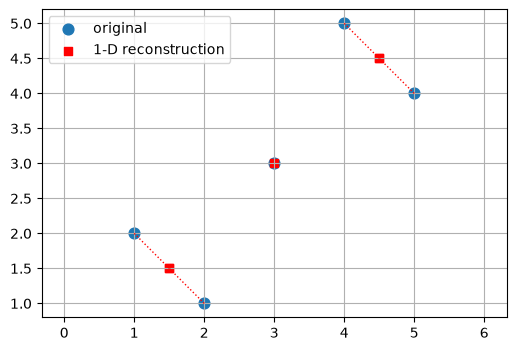

In [14]:
# Check your answer
check(lambda: np.allclose(X_hat[0], [1.5, 1.5]), "reading 1: (1, 2) -> (1.5, 1.5), as on the slide",
      "first row of X_hat should be [1.5, 1.5]")

# Plot the original points and their reconstructions
plt.scatter(X[:, 0], X[:, 1], s=60, label="original")
plt.scatter(X_hat[:, 0], X_hat[:, 1], marker="s", c="red", label="1-D reconstruction")
for a, b in zip(X, X_hat):
    plt.plot([a[0], b[0]], [a[1], b[1]], "r:", lw=1)
plt.axis("equal"); plt.grid(True); plt.legend();

**Question 1.** In words, what does PC1 measure for these two sensors? What does PC2 measure, and why might dropping it be a good idea for sensor data?

Answer:

## Part 2: The same thing in scikit-learn (slide 11)

scikit-learn's `PCA` carries out steps 1-5. As with other scikit-learn models, you create the model, call `.fit(X)`, and then use it.
Attributes learned during fitting end in an underscore:

| attribute | meaning | our NumPy name |
|---|---|---|
| `pca.mean_` | column means | `mean` |
| `pca.components_` | principal axes, one per row | `V.T` |
| `pca.explained_variance_` | eigenvalues | `eigvals` |
| `pca.explained_variance_ratio_` | ratios | `ratio` |

In [15]:
# TODO 7: create a PCA with 2 components and fit it on X
pca = PCA(n_components=2).fit(X)

print("mean_:", pca.mean_)
print("components_:\n", pca.components_)
print("explained_variance_:", pca.explained_variance_)
print("explained_variance_ratio_:", pca.explained_variance_ratio_)

mean_: [3. 3.]
components_:
 [[ 0.707  0.707]
 [-0.707  0.707]]
explained_variance_: [4.5 0.5]
explained_variance_ratio_: [0.9 0.1]


In [16]:
# Check your answer: sklearn agrees with your hand calculation (up to sign)
check(lambda: np.allclose(pca.explained_variance_, eigvals), "your eigenvalues agree with scikit-learn",
      "explained_variance_ should match your eigvals")
check(lambda: np.allclose(np.abs(pca.components_), np.abs(V.T)), "your axes agree with scikit-learn (up to sign)",
      "components_ should match V.T up to sign")

PASS: your eigenvalues agree with scikit-learn
PASS: your axes agree with scikit-learn (up to sign)


In [17]:
# TODO 8: reduce to one component with sklearn, then map back to 2-D
pca1 = PCA(n_components=1).fit(X)
Z1 = pca1.transform(X)               # shape should be (5, 1)
X_hat_sk = pca1.inverse_transform(Z1)  # shape should be (5, 2)

print("Z1 shape:", None if Z1 is None else Z1.shape)
print("X_hat_sk =\n", X_hat_sk)

Z1 shape: (5, 1)
X_hat_sk =
 [[1.5 1.5]
 [1.5 1.5]
 [3.  3. ]
 [4.5 4.5]
 [4.5 4.5]]


In [18]:
# Check your answer
check(lambda: Z1.shape == (5, 1), "Z1 has shape (5, 1)", "Z1 should have shape (5, 1)")
check(lambda: np.allclose(X_hat_sk, X_hat), "the scikit-learn reconstruction equals X_hat", "X_hat_sk should equal X_hat")

PASS: Z1 has shape (5, 1)
PASS: the scikit-learn reconstruction equals X_hat


## Part 3: The 200-point example from the book (slides 3, 12)

The book creates correlated 2-D data by multiplying random numbers by a random 2×2 matrix.
The seed `RandomState(1)` makes the data reproducible.

(200, 2)


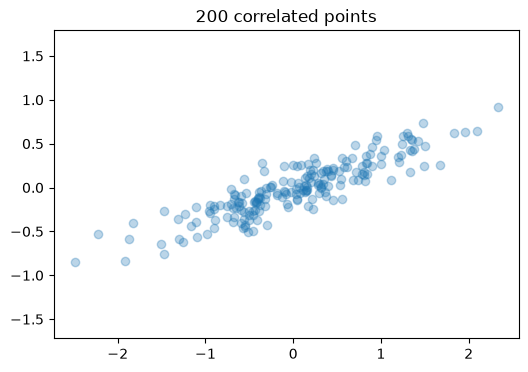

In [19]:
rng = np.random.RandomState(1)
X200 = np.dot(rng.rand(2, 2), rng.randn(2, 200)).T
print(X200.shape)

plt.scatter(X200[:, 0], X200[:, 1], alpha=0.3)
plt.axis("equal"); plt.title("200 correlated points");

In [20]:
# TODO 9: fit a 2-component PCA on X200 and print components_ and explained_variance_
pca200 = PCA(n_components=2).fit(X200)

print(pca200.components_)
print(pca200.explained_variance_)

[[ 0.944  0.329]
 [-0.329  0.944]]
[0.763 0.018]


In [21]:
# Check your answer
check(lambda: np.allclose(pca200.explained_variance_, [0.7625, 0.0185], atol=1e-3),
      "explained_variance_ is about [0.763, 0.018]", "explained_variance_ should be about [0.763, 0.018]")
check(lambda: np.allclose(np.abs(pca200.components_[0]), [0.944, 0.329], atol=1e-3),
      "PC1 matches the book: ±[0.944, 0.329]", "first component should be ±[0.944, 0.329]")

PASS: explained_variance_ is about [0.763, 0.018]
PASS: PC1 matches the book: ±[0.944, 0.329]


Note: the book reports 0.759 for the first variance, while current scikit-learn gives 0.763. Older versions divided by $n$; current versions divide by $n-1$, as in Part 1. Indeed $0.7625 \times 199/200 = 0.7587$. The ratios are unaffected.

### Drawing the principal axes
As in the book, draw each component as an arrow starting at the mean. The direction is a row of `components_` and the length is `3 * sqrt(explained_variance_)`, i.e. three standard deviations.
The function `draw_vector` is provided; write the loop.

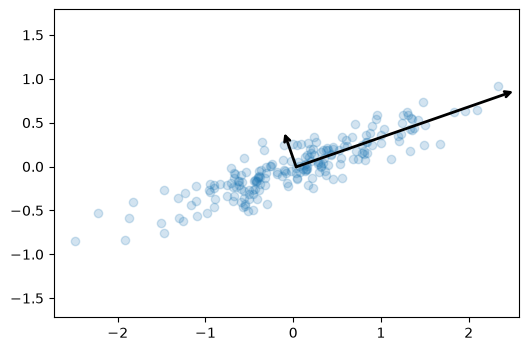

In [22]:
def draw_vector(v0, v1, ax=None):
    ax = ax or plt.gca()
    ax.annotate("", v1, v0, arrowprops=dict(arrowstyle="->", linewidth=2, shrinkA=0, shrinkB=0))

plt.scatter(X200[:, 0], X200[:, 1], alpha=0.2)

# TODO 10: loop over each (variance, direction) pair and draw an arrow from the mean
for length, vector in zip(pca200.explained_variance_, pca200.components_):
    v = vector * 3 * np.sqrt(length)
    draw_vector(pca200.mean_, pca200.mean_ + v)

plt.axis("equal");

In [23]:
# TODO 11: what fraction of variance does PC1 keep? Compute it two ways.
frac_by_hand = pca200.explained_variance_[0] / pca200.explained_variance_.sum()
frac_sklearn = pca200.explained_variance_ratio_[0]

print(frac_by_hand, frac_sklearn)

0.9763410074208768 0.9763410074208768


In [24]:
# Check your answer
check(lambda: np.isclose(frac_by_hand, 0.976, atol=1e-3) and np.isclose(frac_by_hand, frac_sklearn),
      "PC1 keeps about 97.6% of the variance", "both values should be about 0.976")

PASS: PC1 keeps about 97.6% of the variance


### Reducing to one dimension

original shape:    (200, 2)
transformed shape: (200, 1)


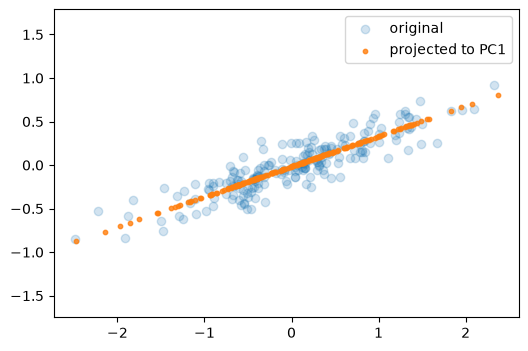

In [25]:
pca200_1 = PCA(n_components=1).fit(X200)
X200_new = pca200_1.inverse_transform(pca200_1.transform(X200))
print("original shape:   ", X200.shape)
print("transformed shape:", pca200_1.transform(X200).shape)

plt.scatter(X200[:, 0], X200[:, 1], alpha=0.2, label="original")
plt.scatter(X200_new[:, 0], X200_new[:, 1], alpha=0.8, s=10, label="projected to PC1")
plt.axis("equal"); plt.legend();

**Question 2.** The light points are spread a little around the dark line. What does that spread represent, and roughly what percentage of the variance is it?

Answer:

## Part 4: Handwritten digits (slides 13–14)

Each image has $8\times8 = 64$ pixels, so each image is a point in 64-dimensional space.
PCA lets us look at the data in two dimensions.

(1797, 64)


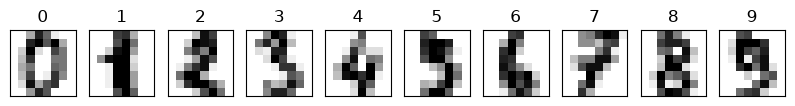

In [26]:
from sklearn.datasets import load_digits
digits = load_digits()
print(digits.data.shape)   # (n_images, n_pixels)

fig, axes = plt.subplots(1, 10, figsize=(10, 1.3), subplot_kw={"xticks": [], "yticks": []})
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="binary")
    ax.set_title(digits.target[i])

In [27]:
# TODO 12: project the 64-D digits down to 2-D
projected = PCA(2).fit_transform(digits.data)

print(digits.data.shape, "->", None if projected is None else projected.shape)

(1797, 64) -> (1797, 2)


PASS: 64 columns -> 2 columns


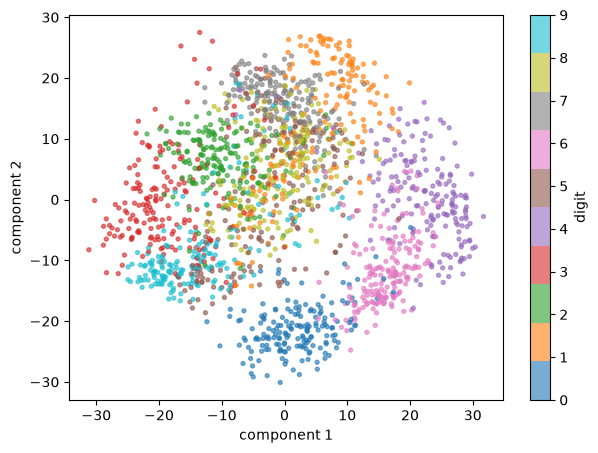

In [28]:
# Check your answer
check(lambda: projected.shape == (1797, 2), "64 columns -> 2 columns", "projected should have shape (1797, 2)")

# Color each point by its true digit. PCA did not use these labels.
plt.figure(figsize=(7, 5))
plt.scatter(projected[:, 0], projected[:, 1], c=digits.target, cmap="tab10", s=8, alpha=0.6)
plt.xlabel("component 1"); plt.ylabel("component 2")
plt.colorbar(label="digit");

**Question 3.** Which digits form clear, separate groups? Which ones overlap? Does that make sense from how the digits look?

Answer:

### Choosing the number of components
Fit PCA with all components and plot the cumulative explained variance, which shows how much of the total variance the first $k$ components keep.

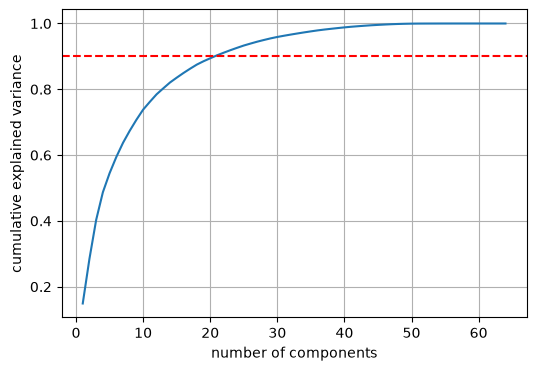

In [29]:
# TODO 13a: fit PCA with all components on digits.data (no argument = keep all)
pca_all = PCA().fit(digits.data)

# TODO 13b: cumulative explained variance
cumvar = np.cumsum(pca_all.explained_variance_ratio_)

plt.plot(np.arange(1, len(cumvar) + 1), cumvar)
plt.axhline(0.90, color="red", ls="--")
plt.xlabel("number of components"); plt.ylabel("cumulative explained variance"); plt.grid(True);

In [30]:
# TODO 14: smallest k such that cumvar >= 0.90
k90 = int(np.argmax(cumvar >= 0.90)) + 1

print("components needed for 90%:", k90)
print("variance kept with 2 components:", round(cumvar[1], 3))
print("variance kept with 10 components:", round(cumvar[9], 3))

components needed for 90%: 21
variance kept with 2 components: 0.285
variance kept with 10 components: 0.738


In [31]:
# Check your answer: sklearn can also pick k for you if you pass a fraction
check(lambda: k90 == PCA(0.90).fit(digits.data).n_components_,
      f"k = {k90}, same as PCA(0.90) picks (the book says about 20)",
      "k90 should equal PCA(0.90).fit(digits.data).n_components_: did you add 1?")

PASS: k = 21, same as PCA(0.90) picks (the book says about 20)


## Part 5: PCA as a noise filter (slide 15)

The signal is concentrated in the components with large variance, while random noise is spread over all components. Reconstructing from the largest components keeps most of the signal and removes much of the noise.

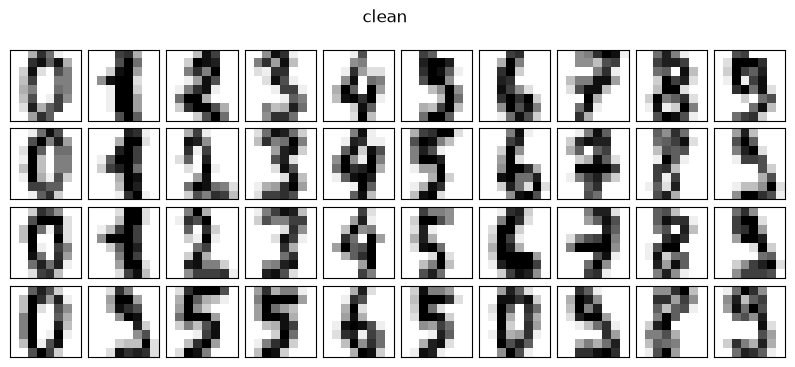

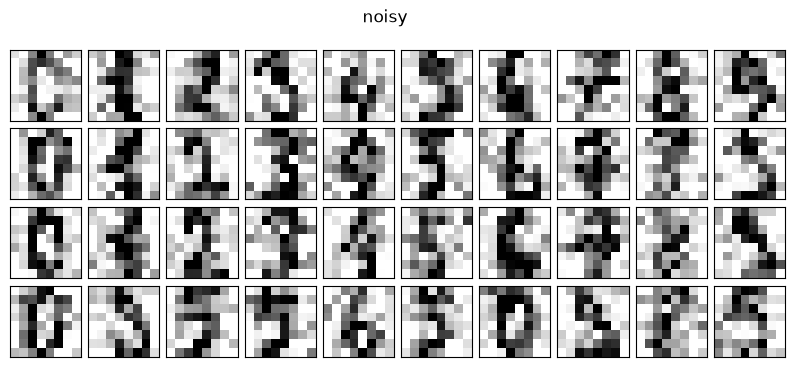

In [32]:
def plot_digits(data, title=""):
    fig, axes = plt.subplots(4, 10, figsize=(10, 4), subplot_kw={"xticks": [], "yticks": []},
                             gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(8, 8), cmap="binary", interpolation="nearest", clim=(0, 16))
    fig.suptitle(title)

np.random.seed(42)
noisy = np.random.normal(digits.data, 4)   # add Gaussian noise with std = 4

plot_digits(digits.data, "clean")
plot_digits(noisy, "noisy")

components kept: 12


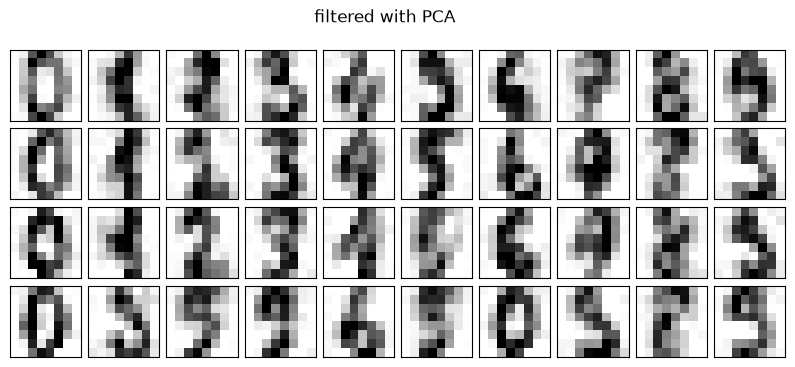

In [33]:
# TODO 15a: fit a PCA on the noisy data that keeps 50% of the variance
pca_noise = PCA(0.50).fit(noisy)
print("components kept:", None if pca_noise is None else pca_noise.n_components_)

# TODO 15b: transform to the reduced space, then inverse_transform back to 64 pixels
filtered = pca_noise.inverse_transform(pca_noise.transform(noisy))

plot_digits(filtered, "filtered with PCA")

In [34]:
# Check your answer: is the filtered version closer to the clean images than the noisy one?
err_noisy = np.mean((noisy - digits.data) ** 2)
err_filtered = np.mean((filtered - digits.data) ** 2)
print(f"mean squared error vs clean:  noisy = {err_noisy:.1f}   filtered = {err_filtered:.1f}")
check(lambda: pca_noise.n_components_ == 12, "12 components, same as the book", "expected 12 components")
check(lambda: err_filtered < err_noisy, "the filtered images are closer to the clean images", "filtered should have lower error")

mean squared error vs clean:  noisy = 16.0   filtered = 7.2
PASS: 12 components, same as the book
PASS: the filtered images are closer to the clean images


**Exercise.** Change `0.50` to `0.30` and to `0.80`. How many components does each keep, and how do the images look? What is the trade-off?

Answer:

## Part 6 (optional): Eigenfaces (slide 16)

This dataset (about 200 MB) is downloaded the first time it is used, so this part requires an internet connection.
The book uses `RandomizedPCA`, which in current scikit-learn is `PCA(svd_solver="randomized")`.

In [35]:
RUN_FACES = False   # set to True to try this part

if RUN_FACES:
    from sklearn.datasets import fetch_lfw_people
    faces = fetch_lfw_people(min_faces_per_person=60)
    print(faces.images.shape)   # (n_faces, height, width)

In [36]:
if RUN_FACES:
    # TODO 16: fit a randomized PCA with 150 components on faces.data
    pca_faces = PCA(150, svd_solver="randomized", random_state=0).fit(faces.data)

    # first 24 "eigenfaces": each component reshaped back into an image
    fig, axes = plt.subplots(3, 8, figsize=(9, 4), subplot_kw={"xticks": [], "yticks": []})
    for i, ax in enumerate(axes.flat):
        ax.imshow(pca_faces.components_[i].reshape(faces.images.shape[1:]), cmap="bone")

    print("variance kept with 150 components:", pca_faces.explained_variance_ratio_.sum())

## Part 7: Cautions (slides 17-18)

### 7a. Scaling
PCA looks for directions of largest variance, so a column recorded in large units can dominate only because of its units.

Below, sensor B is recorded in a unit 1000 times smaller (mK instead of K).

In [37]:
X_units = X.copy()
X_units[:, 1] = X_units[:, 1] * 1000   # sensor B in milli-units

print(PCA(2).fit(X_units).components_)
print(PCA(2).fit(X_units).explained_variance_ratio_)

[[ 0.001  1.   ]
 [ 1.    -0.001]]
[1. 0.]


PC1 is now almost exactly `(0, 1)`; it follows sensor B only because its numbers are larger.
The usual fix is to standardize each column to mean 0 and standard deviation 1 before PCA.

In [38]:
from sklearn.preprocessing import StandardScaler

# TODO 17: standardize X_units, then fit a 2-component PCA on the result
X_std = StandardScaler().fit_transform(X_units)
pca_std = PCA(2).fit(X_std)

print(pca_std.components_)
print(pca_std.explained_variance_ratio_)

[[ 0.707  0.707]
 [-0.707  0.707]]
[0.9 0.1]


In [39]:
# Check your answer
check(lambda: np.allclose(np.abs(pca_std.components_[0]), [0.707, 0.707], atol=1e-3)
              and np.isclose(pca_std.explained_variance_ratio_[0], 0.9),
      "after scaling, PC1 is back to (1,1)/√2 with 90%", "PC1 should be ±(0.707, 0.707) and explain 0.9")

PASS: after scaling, PC1 is back to (1,1)/√2 with 90%


### 7b. Outliers
A single bad reading can change the axes considerably. The cell below adds one faulty reading and compares the results.

In [40]:
X_out = np.vstack([X, [[5, -10]]])   # faulty reading from sensor B

for name, data in [("clean", X), ("with 1 outlier", X_out)]:
    p = PCA(2).fit(data)
    print(f"{name:15s} PC1 = {p.components_[0]}   ratio = {p.explained_variance_ratio_}")

clean           PC1 = [0.707 0.707]   ratio = [0.9 0.1]
with 1 outlier  PC1 = [-0.098  0.995]   ratio = [0.927 0.073]


**Question 4.** How much did one bad reading change PC1? In a real data pipeline, what would you do before running PCA?

Answer:

## Part 8: Final exercise (slide 19)

In this data sensor B agrees less with sensor A. Before computing, predict whether PC1 will explain more or less than 90% of the variance.

In [41]:
X_new = np.array([[1, 4],
                  [2, 1],
                  [3, 3],
                  [4, 2],
                  [5, 5]], dtype=float)

# TODO 18: using only NumPy (Part 1 steps), compute the eigenvalues (largest first)
#          and the explained variance ratio for X_new.
Xc_new = X_new - X_new.mean(axis=0)
C_new = Xc_new.T @ Xc_new / (len(X_new) - 1)
eigvals_new = np.sort(np.linalg.eigvalsh(C_new))[::-1]
ratio_new = eigvals_new / eigvals_new.sum()

print("eigenvalues:", eigvals_new)
print("ratio:", ratio_new)

eigenvalues: [3.25 1.75]
ratio: [0.65 0.35]


In [42]:
# Check your answer against sklearn
check(lambda: np.allclose(eigvals_new, PCA().fit(X_new).explained_variance_),
      "your eigenvalues match sklearn", "eigenvalues don't match PCA().fit(X_new).explained_variance_")

PASS: your eigenvalues match sklearn


**Question 5.** Compare with the original data (4.5 and 0.5, 90%). Why did PC1 lose importance? Would you still reduce this data to one dimension?

Answer:

### Summary
PCA centers the data, computes the covariance matrix, finds its eigenvectors, and projects the data onto them. The eigenvectors give the new directions and the eigenvalues give the variance along each one. The cumulative explained variance helps decide how many components to keep. In scikit-learn the workflow is `PCA(k).fit(X)` followed by `transform` and `inverse_transform`. Standardize columns measured in different units, and check for outliers before applying PCA.